# 09 - Gaussian Naive Bayes trên Customer dataset

Mục tiêu: dự đoán `Purchased` từ `Gender`, `Age`, `EstimatedSalary`, bỏ `User ID`.

## 1. Load data và EDA ngắn

Shape: (400, 5)
Missing values:
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64
Target distribution:
Purchased
0    257
1    143
Name: count, dtype: int64


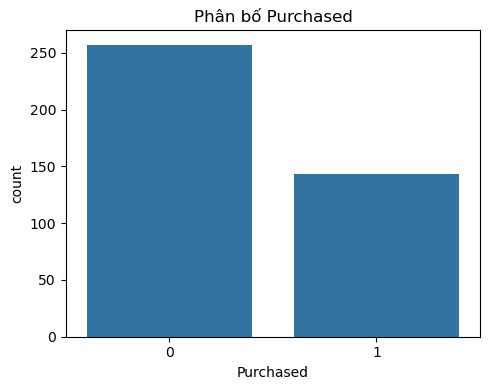

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'figures'
FIG_DIR.mkdir(exist_ok=True)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

df = pd.read_csv(DATA_DIR / 'customer.csv')
print('Shape:', df.shape)
print('Missing values:'); print(df.isna().sum())
print('Target distribution:'); print(df['Purchased'].value_counts())
assert df.columns.tolist() == ['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased']
assert len(df) == 400
X = df.drop(columns=['User ID', 'Purchased']); y = df['Purchased']
plt.figure(figsize=(5, 4)); sns.countplot(data=df, x='Purchased'); plt.title('Phân bố Purchased'); plt.tight_layout(); plt.savefig(FIG_DIR / '09_customer_target_distribution.png', dpi=150); plt.show()


## 2. Tiền xử lý, train và chọn có/không scale

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
categorical = ['Gender']; numeric = ['Age', 'EstimatedSalary']
preprocess = ColumnTransformer([('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), categorical), ('num', 'passthrough', numeric)])
pipe = Pipeline([('preprocess', preprocess), ('classifier', GaussianNB())])
grid = GridSearchCV(pipe, {'preprocess__num': ['passthrough', StandardScaler()]}, scoring='accuracy', cv=5, n_jobs=-1, error_score=np.nan, return_train_score=True)
grid.fit(X_train, y_train)
model = grid.best_estimator_
print('Best params:', grid.best_params_)
print('Best CV accuracy:', round(grid.best_score_, 4))
comparison = pd.DataFrame(grid.cv_results_)[['param_preprocess__num', 'mean_test_score', 'std_test_score']]
comparison['scale'] = comparison['param_preprocess__num'].map(lambda value: 'có StandardScaler' if value != 'passthrough' else 'không scale')
print(comparison[['scale', 'mean_test_score', 'std_test_score']].round(4).to_string(index=False))


Best params: {'preprocess__num': 'passthrough'}
Best CV accuracy: 0.8875
            scale  mean_test_score  std_test_score
      không scale           0.8875           0.023
có StandardScaler           0.8875           0.023


## 3. Đánh giá và nhận xét

accuracy     0.8750
precision    0.8519
recall       0.7931
f1           0.8214
roc_auc      0.9500
dtype: float64
              precision    recall  f1-score   support

           0       0.89      0.92      0.90        51
           1       0.85      0.79      0.82        29

    accuracy                           0.88        80
   macro avg       0.87      0.86      0.86        80
weighted avg       0.87      0.88      0.87        80



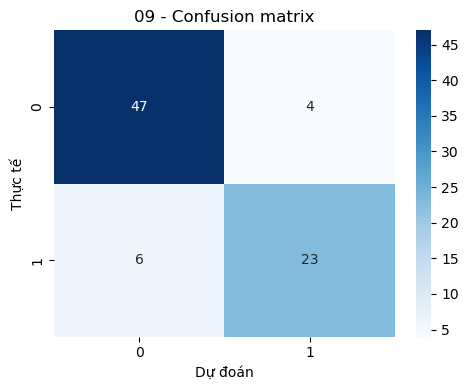

Nhận xét: GaussianNB phù hợp và các biến số được mô hình hóa theo phân phối Gaussian; Gender được one-hot encode.
StandardScaler được chọn qua 5-fold CV: không
Đã cập nhật: D:\ML_Lab_Group_2026\Lab05_ModelTraining\Lab05\figures\results_summary.csv


In [3]:
y_pred = model.predict(X_test); y_score = model.predict_proba(X_test)[:, 1]
metrics = {'accuracy': accuracy_score(y_test, y_pred), 'precision': precision_score(y_test, y_pred), 'recall': recall_score(y_test, y_pred), 'f1': f1_score(y_test, y_pred), 'roc_auc': roc_auc_score(y_test, y_score)}
print(pd.Series(metrics).round(4)); print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1], yticklabels=[0, 1]); plt.xlabel('Dự đoán'); plt.ylabel('Thực tế'); plt.title('09 - Confusion matrix'); plt.tight_layout(); plt.savefig(FIG_DIR / '09_customer_confusion_matrix.png', dpi=150); plt.show()
scale_selected = grid.best_params_['preprocess__num'] != 'passthrough'
print('Nhận xét: GaussianNB phù hợp và các biến số được mô hình hóa theo phân phối Gaussian; Gender được one-hot encode.')
print('StandardScaler được chọn qua 5-fold CV:', 'có' if scale_selected else 'không')
summary_path = FIG_DIR / 'results_summary.csv'; columns = ['notebook', 'dataset', 'model', 'best_params', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc']
summary = pd.read_csv(summary_path) if summary_path.exists() else pd.DataFrame(columns=columns)
summary = summary[summary['notebook'] != '09_customer_nb']
summary.loc[len(summary)] = ['09_customer_nb', 'customer.csv', 'GaussianNB', str(grid.best_params_), *[metrics[c] for c in columns[4:]]]
summary.to_csv(summary_path, index=False); print('Đã cập nhật:', summary_path)
